# 3 · Simulation-based inference

This route does not evaluate the trajectory likelihood. It simulates many independent
movies from a stated prior and learns how their **observed-data summaries** relate to
parameter values. Two implementations are included:

- Prior-bank rejection ABC: retain simulated movies whose summaries are nearby.
- A **custom PyTorch mixture-density network (MDN)**: learn a joint conditional
  density on six parameters. This is not the third-party `sbi` package.

Both target a summary posterior, which can lose information relative to full data.
The neural posterior uses a bounded transform, includes its density Jacobian, and
generates correlated parameter draws through full component covariance matrices.

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
from io import BytesIO
import json
import os
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'pyproject.toml').is_file()
             and (p / 'src' / 'motility_inference').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Launch this notebook from the project or its notebooks directory.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
RESULTS = ROOT / 'results' / 'synthetic_v1'
RUN_TRAINING = False  # Large simulation banks and MCMC are never launched by default.
(ROOT / '.cache').mkdir(exist_ok=True)
os.environ.setdefault('XDG_CACHE_HOME', str(ROOT / '.cache'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache' / 'matplotlib'))

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
from motility_inference.simulator import SimConfig, simulate, load_dataset, proximity
from motility_inference.priors import PARAMETER_NAMES, PRIOR_LOW, PRIOR_HIGH, scenario_theta

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})

def show(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format='png', dpi=130, bbox_inches='tight')
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

def read_json(name):
    path = RESULTS / name
    if not path.is_file():
        return None
    try:
        return json.loads(path.read_text())
    except json.JSONDecodeError:
        print(f'{name} is being updated; rerun this cell after the benchmark finishes.')
        return None

print('Project:', ROOT)
print('Cached results:', RESULTS)

Project: /Users/marsian/PhD_LifeSciRes/cell_motility
Cached results: /Users/marsian/PhD_LifeSciRes/cell_motility/results/synthetic_v1


In [2]:
import torch
torch.set_num_threads(2)
from motility_inference.summaries import summarize
from motility_inference.sbi import generate_bank, train_posterior, NeuralPosterior, abc_samples
bank_path = RESULTS / 'training_bank.npz'
if bank_path.is_file():
    with np.load(bank_path, allow_pickle=False) as z:
        bank_theta, bank_summaries = z['theta'].copy(), z['summaries'].copy()
        bank_config = SimConfig(**json.loads(str(z['config_json'])))
    print('Loaded independent dataset-level simulation bank:', bank_summaries.shape)
else:
    bank_config = SimConfig()
    bank_theta, bank_summaries = generate_bank(256, bank_config, seed=301)
    print('DEMONSTRATION ONLY: 256-movie bank; this is not the completed validation study.')
example_path = RESULTS / 'examples' / 'combined.npz'
data = load_dataset(example_path) if example_path.is_file() else simulate(scenario_theta('combined'), bank_config, seed=302)
if data['config'] != asdict(bank_config):
    raise ValueError('Example observation protocol differs from the simulation bank.')
observed, names = summarize(data, return_names=True)
print('Observed-only summary dimensions:', len(observed))
display(pd.DataFrame({'feature': names, 'value': observed}).head(20))

Loaded independent dataset-level simulation bank: (16000, 82)
Observed-only summary dimensions: 82


,feature,value
0,all.fraction,1.000000
1,all.log_msd_lag1,0.233029
2,all.log_msd_lag2,1.270493
3,all.log_msd_lag4,2.379009
4,all.log_msd_lag8,3.442656
5,all.log_msd_lag16,4.407198
6,all.log_step_fourth,1.236499
7,all.cosine_lag1,0.319947
8,all.autocorrelation_lag1,0.409256
9,all.cosine_lag2,0.283238


Summaries include distance-stratified multi-lag MSD, increment correlations,
turning/reversals, radial displacement, within-cell contrasts, and exposure/dwell.
Distance strata use the beginning of each interval, not eventual successful contact.
Latent velocity, truth parameters, true gates, and random cell effects are excluded.
Lags are in frames, so a different imaging cadence requires a matched simulation bank.

In [3]:
abc = abc_samples(observed, bank_theta, bank_summaries,
                  n_accept=min(256, max(16, len(bank_theta)//20)))
print('ABC accepted fraction:', abc['acceptance_fraction'])
print('ABC standardized-summary tolerance:', abc['epsilon'])
print('These are actual accepted prior samples; nonzero tolerance makes ABC approximate.')
checkpoint = RESULTS / 'neural_posterior.pt'
model = None
if checkpoint.is_file() and bank_path.is_file():
    model = NeuralPosterior.load(checkpoint)
    print('Loaded trained posterior; no training performed.')
elif RUN_TRAINING:
    model = train_posterior(bank_theta, bank_summaries, seed=303,
                            max_epochs=60, hidden=64, components=2)
    print('Small demonstration training only; no validated performance claim.')
else:
    print('Neural checkpoint absent. Training is disabled by RUN_TRAINING=False.')
neural_draws = model.sample(observed, n=1500, seed=304) if model is not None else None
if model is not None:
    display(pd.Series(model.input_diagnostics(observed)))

ABC accepted fraction: 0.016
ABC standardized-summary tolerance: 0.5852780471946902
These are actual accepted prior samples; nonzero tolerance makes ABC approximate.
Loaded trained posterior; no training performed.


maximum_absolute_standardized_summary    1.459613
fraction_beyond_4_training_sd                 0.0
warning                                     False
dtype: object

Use the high-level entry point for application. It checks actual array dimensions,
time spacing, near/far information, and the observation protocol against the bank.
Matching inputs can yield an **advisory**, not experimental proof. A protocol shift
raises an error by default. Deliberately allowing a stress test still returns an
explicit abstention and no supported effects.

In [4]:
from motility_inference.framework import infer_neural
if checkpoint.is_file() and (RESULTS / 'bank_metadata.json').is_file():
    observed_only = {key: data[key] for key in ('positions', 'targets', 'times', 'config')}
    advisory = infer_neural(observed_only, checkpoint, n_draws=500, seed=305)
    display(pd.Series({'matched_decision': advisory['decision'],
                       'abstained': advisory['abstained'],
                       'candidate_effects': advisory['candidate_effects'],
                       'supported_effects': advisory['supported_effects']}))
    noise_path = RESULTS / 'examples' / 'noisy_null.npz'
    noisy = load_dataset(noise_path) if noise_path.is_file() else simulate(
        scenario_theta('null'), replace(bank_config, localization_sd=0.6), seed=306)
    noisy_observed = {key: noisy[key] for key in ('positions', 'targets', 'times', 'config')}
    try:
        infer_neural(noisy_observed, checkpoint, n_draws=200, seed=307)
    except ValueError as error:
        print('Expected protocol guard:', error)
    stress = infer_neural(noisy_observed, checkpoint, allow_protocol_shift=True,
                          n_draws=300, seed=308)
    display(pd.Series({'stress_decision': stress['decision'], 'abstained': stress['abstained'],
                       'supported_effects': stress['supported_effects']}))
else:
    print('Guard demonstration requires the trained checkpoint and bank_metadata.json.')

matched_decision                            advisory_effect
abstained                                             False
candidate_effects    [delta_speed, delta_tau, delta_jitter]
supported_effects                                        []
dtype: object

Expected protocol guard: observation protocol differs from neural training: localization_sd. Retrain for this protocol, or explicitly allow_protocol_shift=True for an abstaining stress analysis.


stress_decision      protocol_shift_unvalidated
abstained                                  True
supported_effects                            []
dtype: object

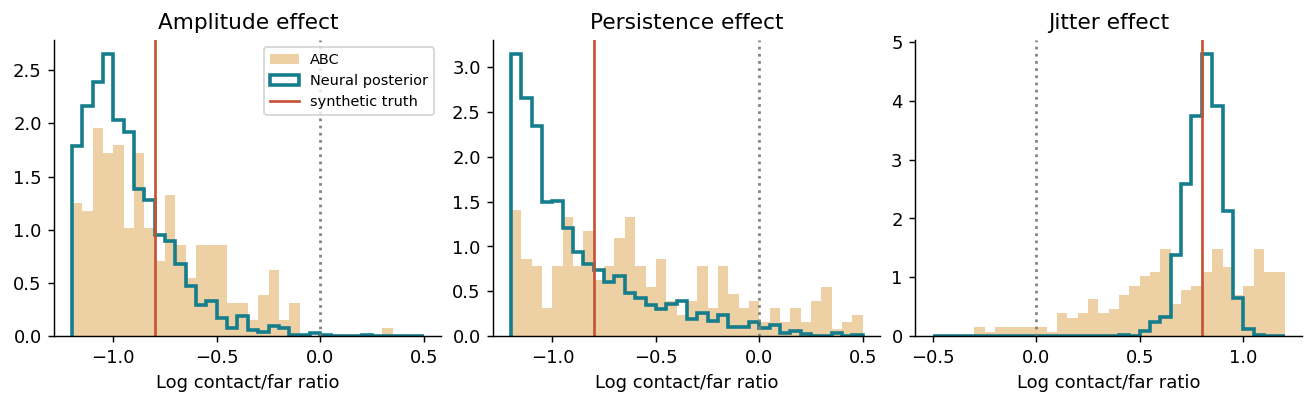

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3), constrained_layout=True)
for ax, j, label in zip(axes, (3,4,5), ('Amplitude effect', 'Persistence effect', 'Jitter effect')):
    bins = np.linspace(PRIOR_LOW[j], PRIOR_HIGH[j], 35)
    ax.hist(abc['samples'][:, j], bins=bins, density=True, alpha=.45,
            color='#d89b39', label='ABC')
    if neural_draws is not None:
        ax.hist(neural_draws[:, j], bins=bins, density=True, histtype='step',
                linewidth=2, color='#167d8d', label='Neural posterior')
    ax.axvline(data['theta'][j], color='#c65335', label='synthetic truth')
    ax.axvline(0, color='grey', ls=':')
    ax.set(title=label, xlabel='Log contact/far ratio')
axes[0].legend(fontsize=8)
show(fig)

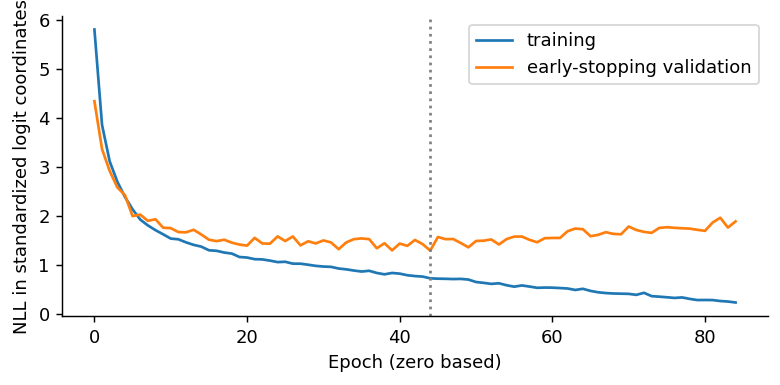

Reproduce training explicitly from the project root:
python scripts/run_synthetic_benchmark.py --stage bank --n-train 16000
python scripts/run_synthetic_benchmark.py --stage train --epochs 300
python scripts/run_synthetic_benchmark.py --stage evaluate --n-test 256 --replicates 32


In [6]:
training = read_json('training.json')
if training is not None:
    history = training['history']
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(history['train_nll'], label='training')
    ax.plot(history['validation_nll'], label='early-stopping validation')
    ax.axvline(history['best_epoch'], color='grey', ls=':')
    ax.set(xlabel='Epoch (zero based)', ylabel='NLL in standardized logit coordinates')
    ax.legend()
    show(fig)
else:
    print('No saved training curve.')
print('Reproduce training explicitly from the project root:')
print('python scripts/run_synthetic_benchmark.py --stage bank --n-train 16000')
print('python scripts/run_synthetic_benchmark.py --stage train --epochs 300')
print('python scripts/run_synthetic_benchmark.py --stage evaluate --n-test 256 --replicates 32')

Early-stopping validation chooses weights; it is **not** the independent calibration
set. Calibration, null false positives, and alternatives are evaluated on entirely
new simulated movies. Coverage alone is insufficient: an unchanged prior can have
correct coverage, so notebook 4 also reports widths and recovery errors.

An input-range warning is only a crude diagnostic; its absence does not establish
model adequacy. Adhesion, spontaneous state changes, or altered noise can make
confident inference wrong. Sequential rounds of SBI would refine a computational
posterior and should not be confused with inference at successive biological times.

General workflow reference: [SBI diagnostics and validation guidance](https://sbi.readthedocs.io/en/latest/how_to_guide.html).